In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 83.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.8.93
    Uninstalling nvidia-nvjitlink-cu12-12.8.93:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.8.93
  Attempting uninstall: nvidia-curand-cu12
    Found existing installation: nvidia-curand-cu12 10.3.9.90
    Uninstalling nvidia-curand-cu12-10.3.

In [2]:
import os
import sys
import cv2
import numpy as np
import csv
from glob import glob
from tqdm.notebook import tqdm
from ultralytics import SAM
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random
import torch
import re

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
# Set the seed value
SEED = 42  

# Python’s built-in random module
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Ensure deterministic behavior in PyTorch
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Set PYTHONHASHSEED to ensure consistent behavior in hash-based operations
os.environ["PYTHONHASHSEED"] = str(SEED)

In [4]:
# Paths and models
image_dir = "/kaggle/input/rasoul-b-obb/dataset/images/test"
gt_mask_dir_npy = "/kaggle/input/rasouldatav2/HemoricaV1-masks"

models = [
    "yolov8n-obb", "yolov8s-obb", "yolov8m-obb",
    "yolo11n-obb", "yolo11s-obb", "yolo11m-obb"
]

output_dir = "/kaggle/working/myplots"
os.makedirs(output_dir, exist_ok=True)

In [5]:
# SAM model (load once)
sam_model = SAM('sam2.1_t.pt')
sam_model.info()

/usr/local/lib/python3.11/dist-packages/ultralytics/models/sam/build.py:305: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(f)["model"]


Model summary: 307 layers, 38,962,498 parameters, 38,962,498 gradients


(307, 38962498, 38962498, 0.0)

In [6]:
def extract_patient_name(image_name):
    name = os.path.basename(str(image_name)).replace(".png", "")
    name = re.sub(r"-\d+_\d+", "", name)  # remove "-digits_slice"
    name = re.sub(r"-\d+", "", name)      # remove "-digits"
    name = re.sub(r"_\d+$", "", name)     # remove "_slice"
    return name.strip()

In [7]:
# Function to outline GT mask with class color
def outline_gt_mask(gt_mask, color, thickness=2):
    contours, _ = cv2.findContours(gt_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    outline_mask = np.zeros((gt_mask.shape[0], gt_mask.shape[1], 3), dtype=np.uint8)
    cv2.drawContours(outline_mask, contours, -1, color, thickness)
    return outline_mask


🔄 Processing YOLO model: yolov8n-obb


yolov8n-obb images:   0%|          | 0/2429 [00:00<?, ?it/s]

📢 Overall Dice (Micro-average) for yolov8n-obb: 0.7182
📢 Overall IoU (Micro-average) for yolov8n-obb: 0.5603
📊 Slice-wise Mean Dice (Macro-average) for yolov8n-obb: 0.5938
📊 Slice-wise Mean IoU (Macro-average) for yolov8n-obb: 0.5142
📄 Performing patient-wise analysis for yolov8n-obb...
📄 Patientwise scores for yolov8n-obb saved.


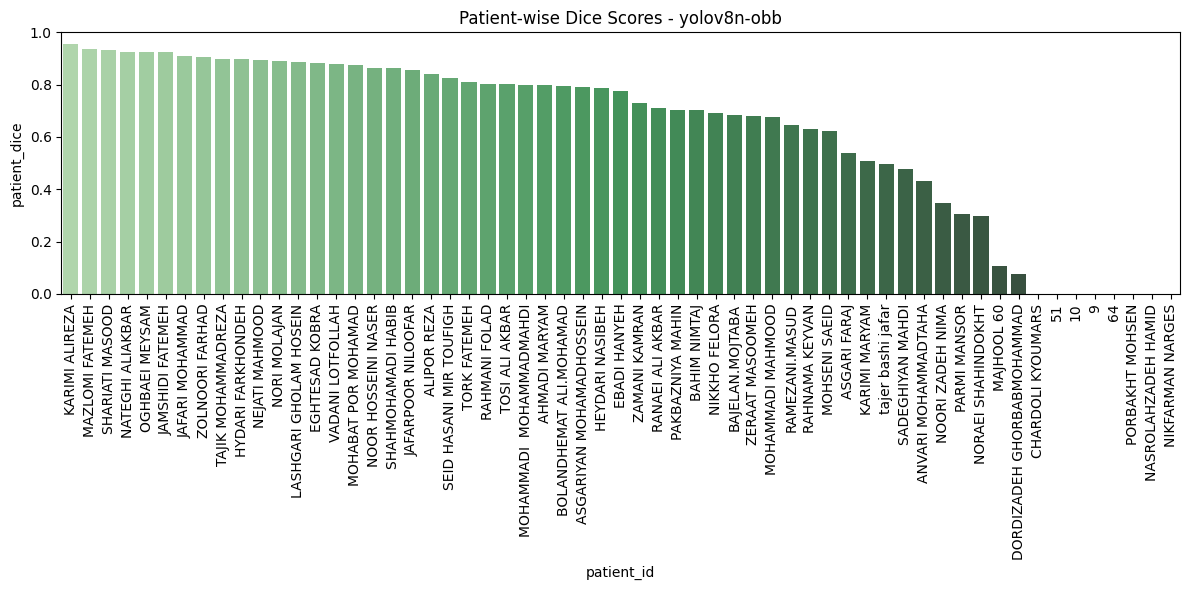

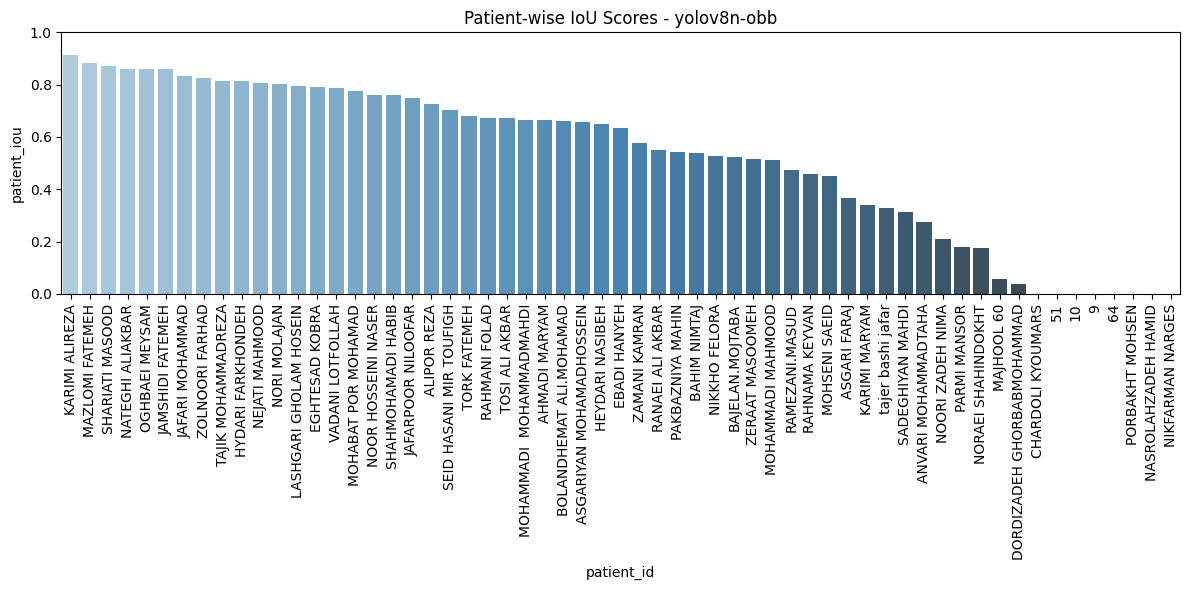

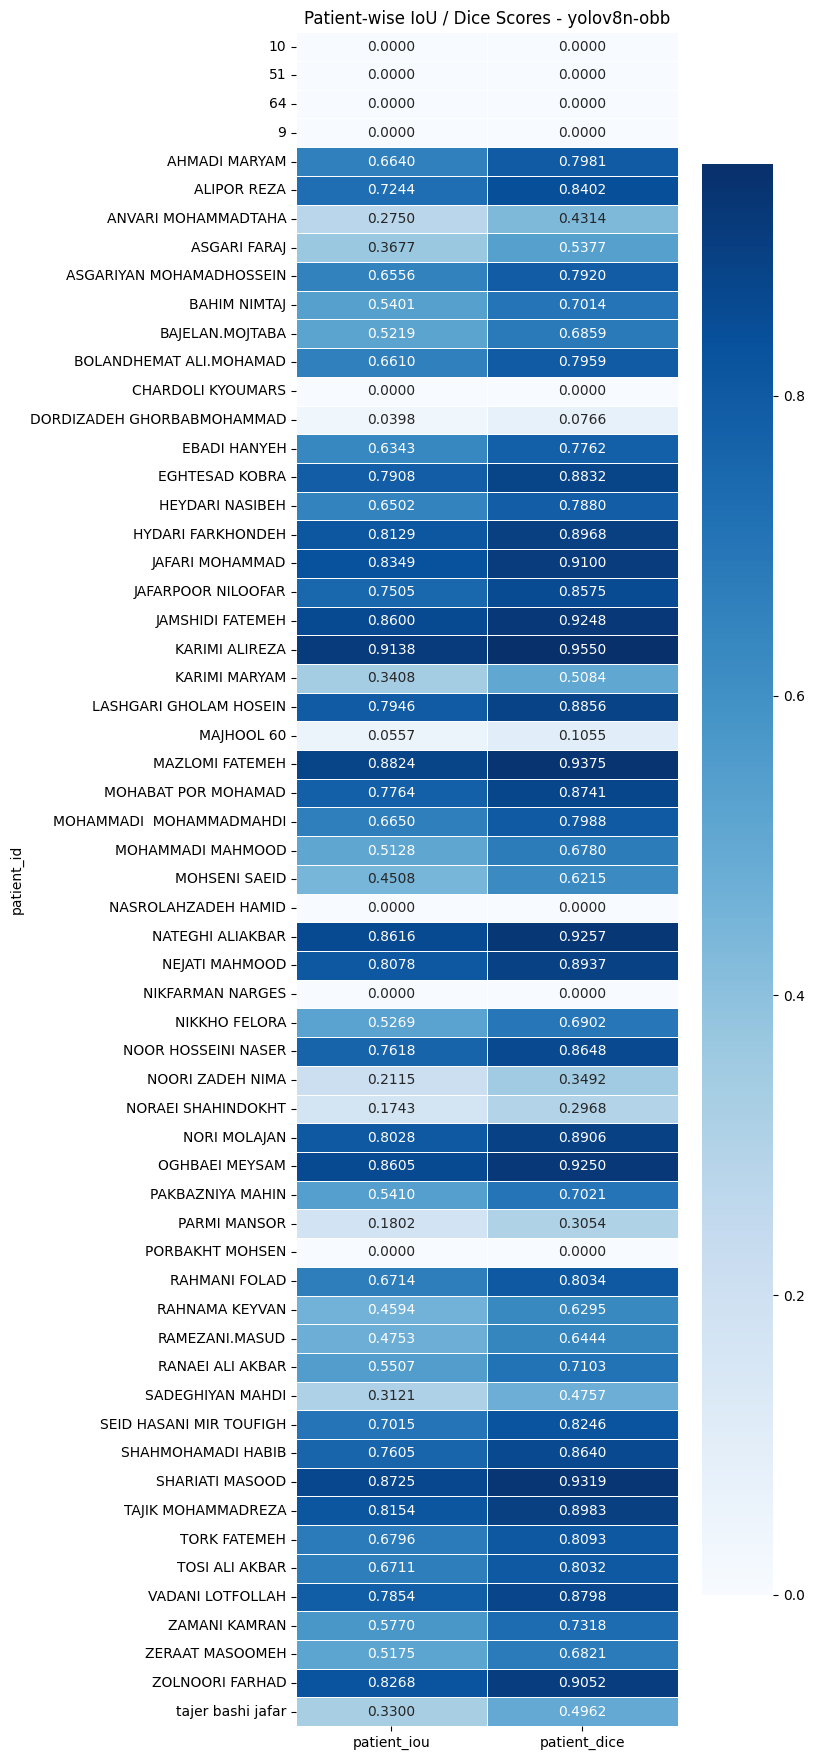


🔄 Processing YOLO model: yolov8s-obb


yolov8s-obb images:   0%|          | 0/2429 [00:00<?, ?it/s]

📢 Overall Dice (Micro-average) for yolov8s-obb: 0.7019
📢 Overall IoU (Micro-average) for yolov8s-obb: 0.5408
📊 Slice-wise Mean Dice (Macro-average) for yolov8s-obb: 0.5774
📊 Slice-wise Mean IoU (Macro-average) for yolov8s-obb: 0.4972
📄 Performing patient-wise analysis for yolov8s-obb...
📄 Patientwise scores for yolov8s-obb saved.


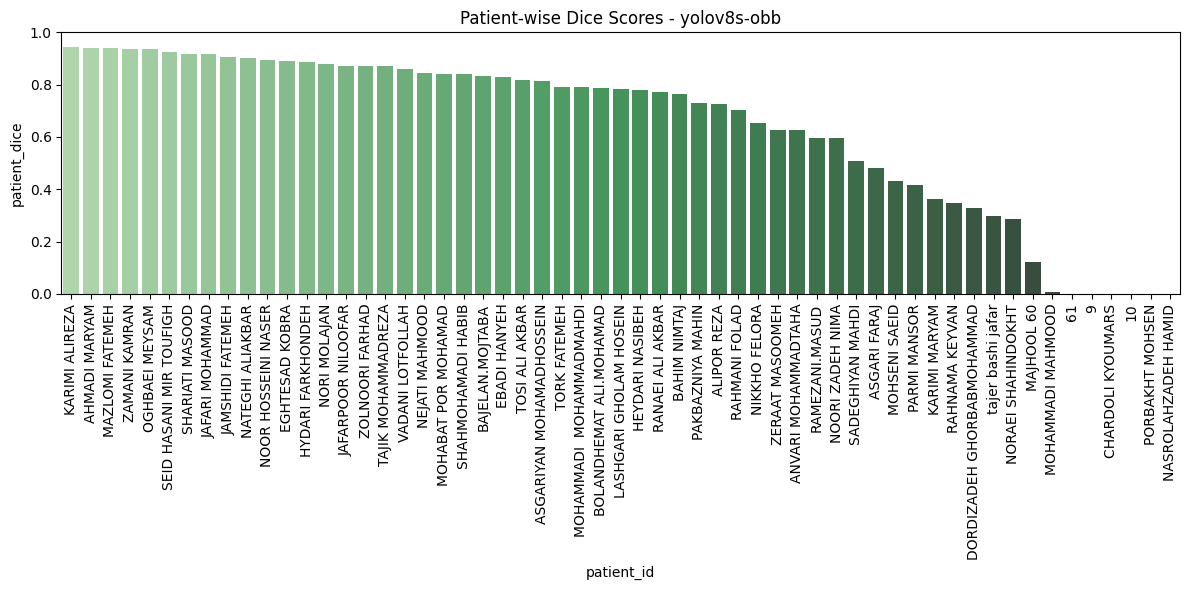

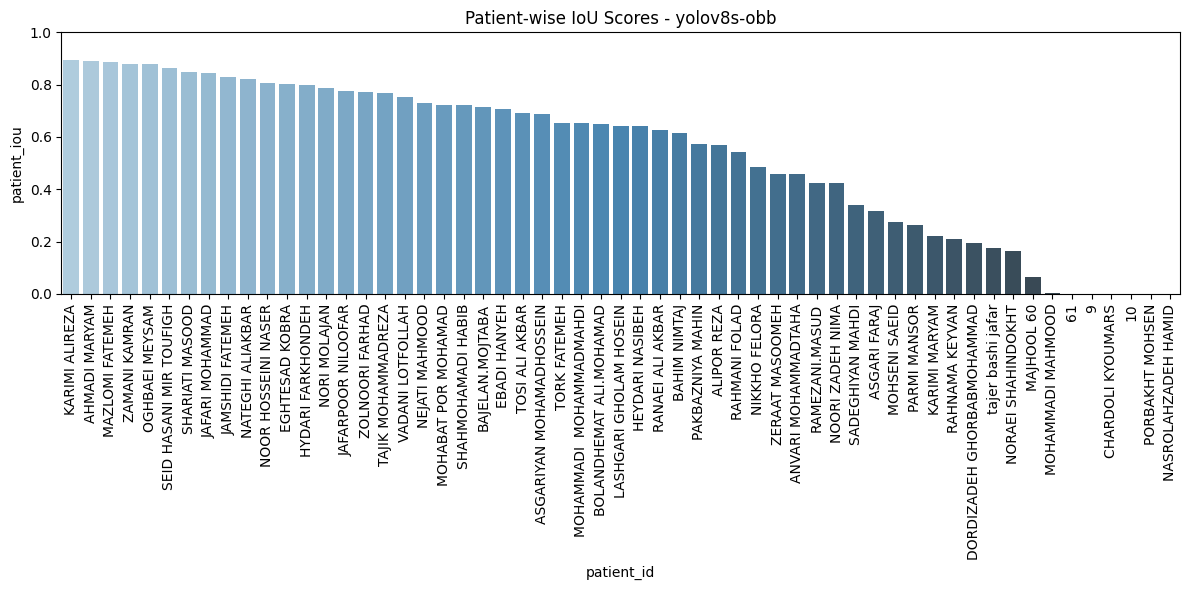

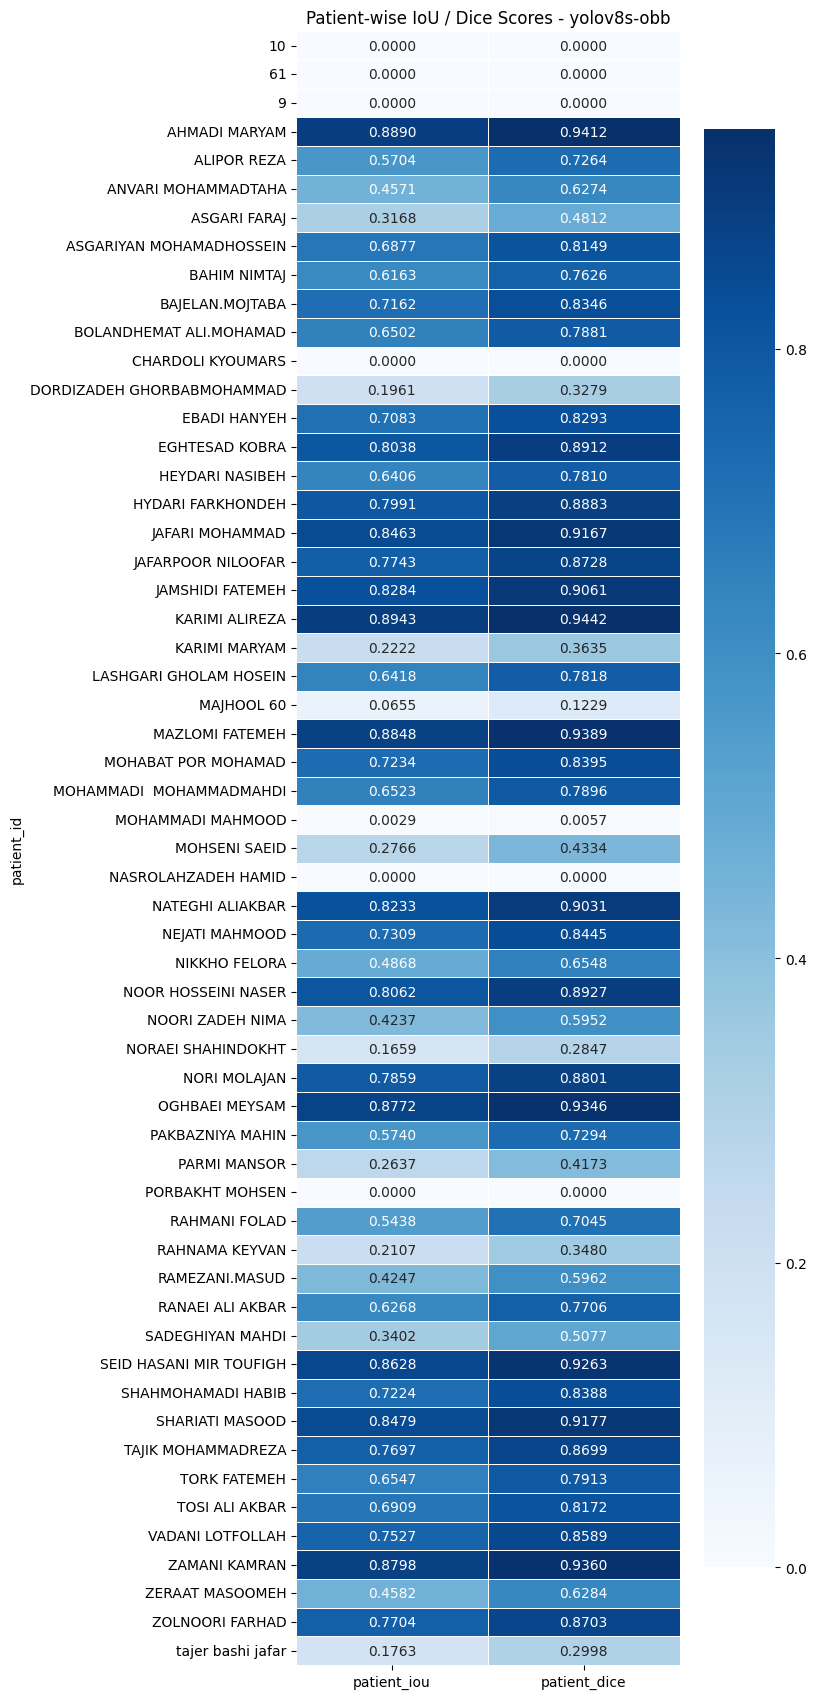


🔄 Processing YOLO model: yolov8m-obb


yolov8m-obb images:   0%|          | 0/2429 [00:00<?, ?it/s]

📢 Overall Dice (Micro-average) for yolov8m-obb: 0.7338
📢 Overall IoU (Micro-average) for yolov8m-obb: 0.5796
📊 Slice-wise Mean Dice (Macro-average) for yolov8m-obb: 0.5836
📊 Slice-wise Mean IoU (Macro-average) for yolov8m-obb: 0.5064
📄 Performing patient-wise analysis for yolov8m-obb...
📄 Patientwise scores for yolov8m-obb saved.


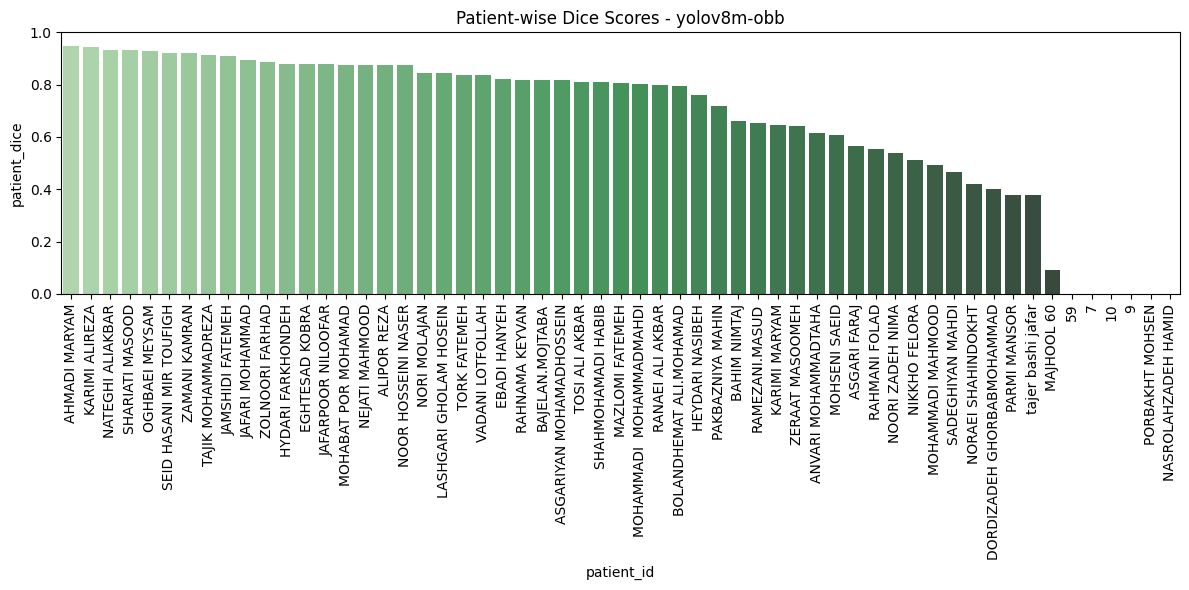

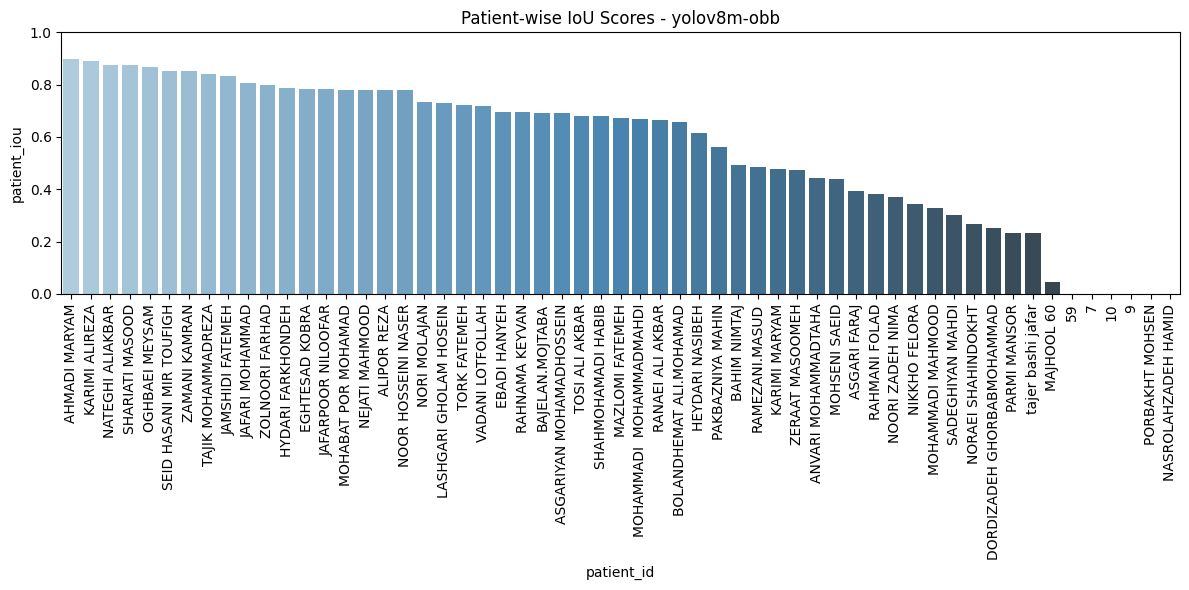

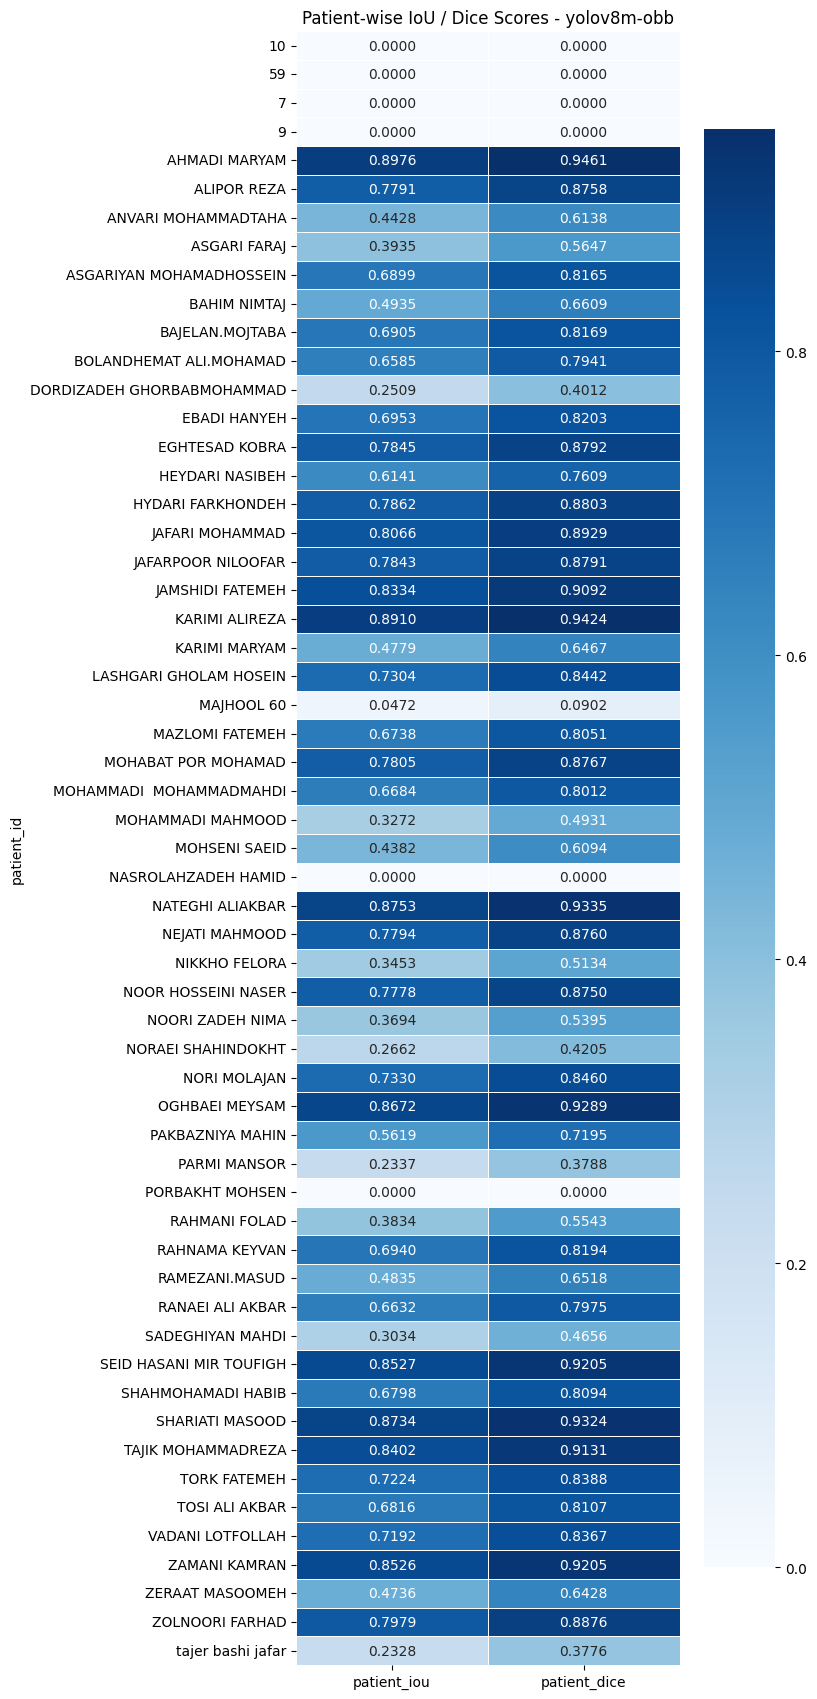


🔄 Processing YOLO model: yolo11n-obb


yolo11n-obb images:   0%|          | 0/2429 [00:00<?, ?it/s]

📢 Overall Dice (Micro-average) for yolo11n-obb: 0.7342
📢 Overall IoU (Micro-average) for yolo11n-obb: 0.5800
📊 Slice-wise Mean Dice (Macro-average) for yolo11n-obb: 0.5956
📊 Slice-wise Mean IoU (Macro-average) for yolo11n-obb: 0.5139
📄 Performing patient-wise analysis for yolo11n-obb...
📄 Patientwise scores for yolo11n-obb saved.


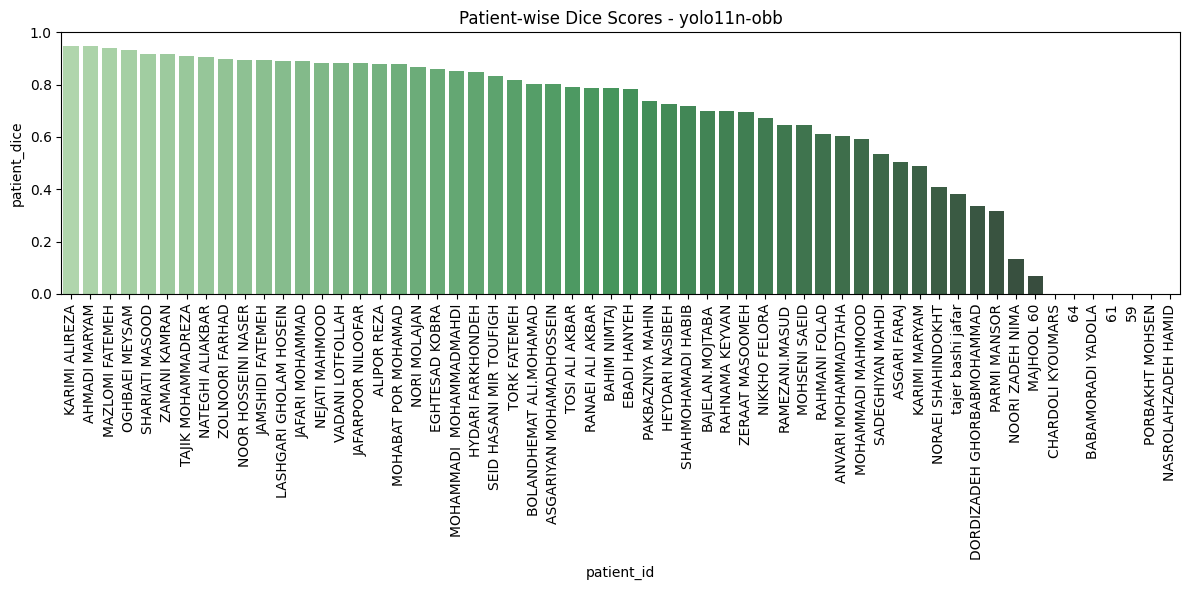

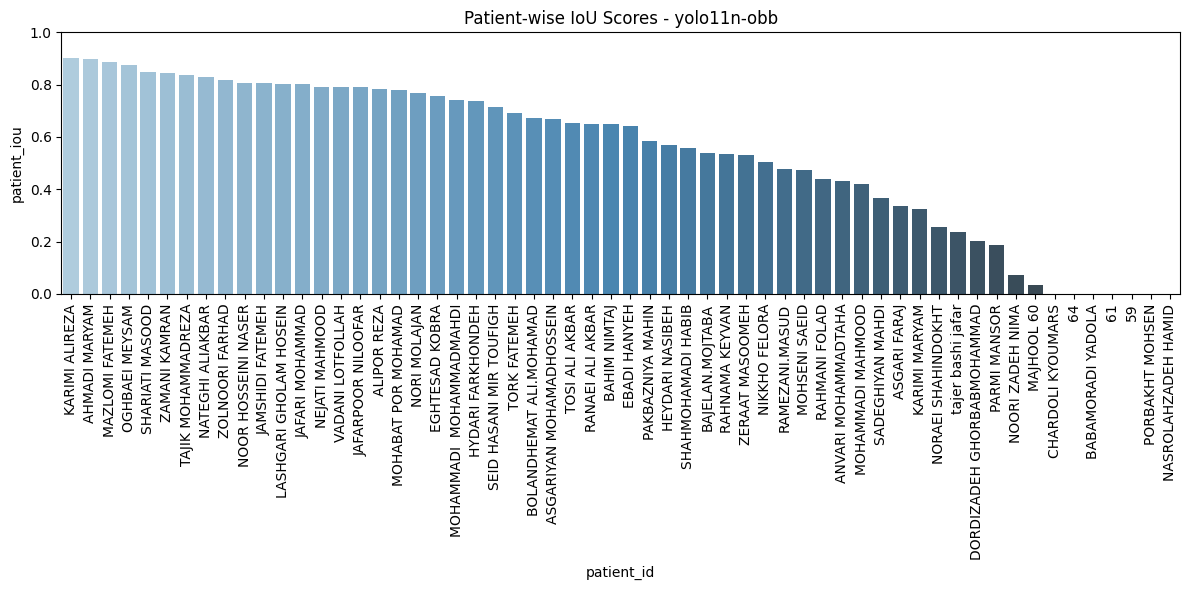

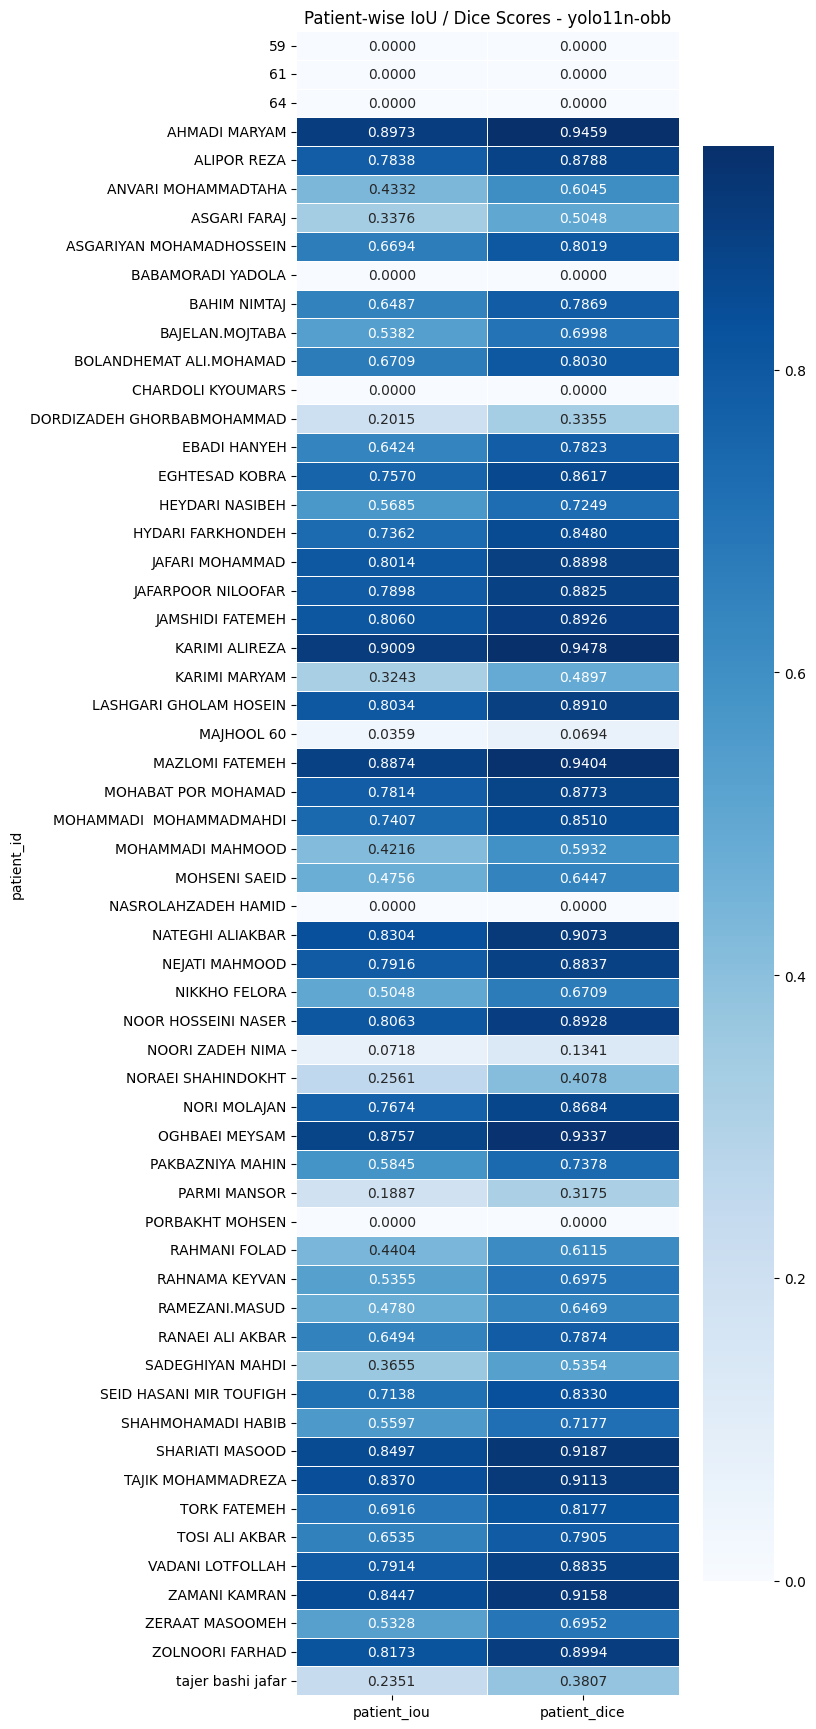


🔄 Processing YOLO model: yolo11s-obb


yolo11s-obb images:   0%|          | 0/2429 [00:00<?, ?it/s]

📢 Overall Dice (Micro-average) for yolo11s-obb: 0.6959
📢 Overall IoU (Micro-average) for yolo11s-obb: 0.5337
📊 Slice-wise Mean Dice (Macro-average) for yolo11s-obb: 0.5547
📊 Slice-wise Mean IoU (Macro-average) for yolo11s-obb: 0.4771
📄 Performing patient-wise analysis for yolo11s-obb...
📄 Patientwise scores for yolo11s-obb saved.


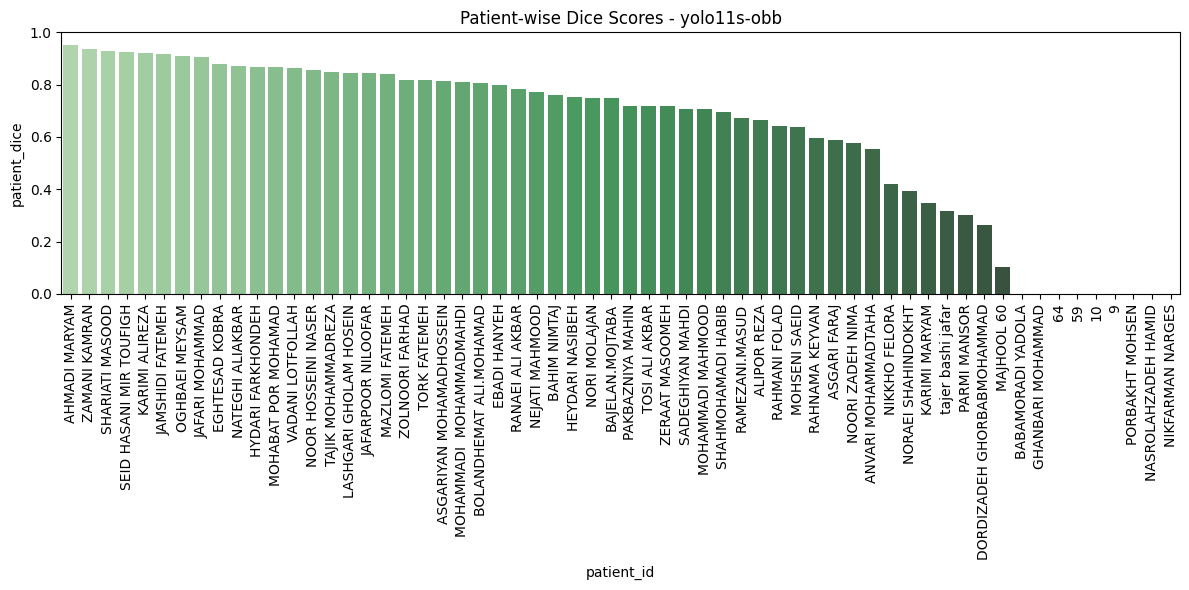

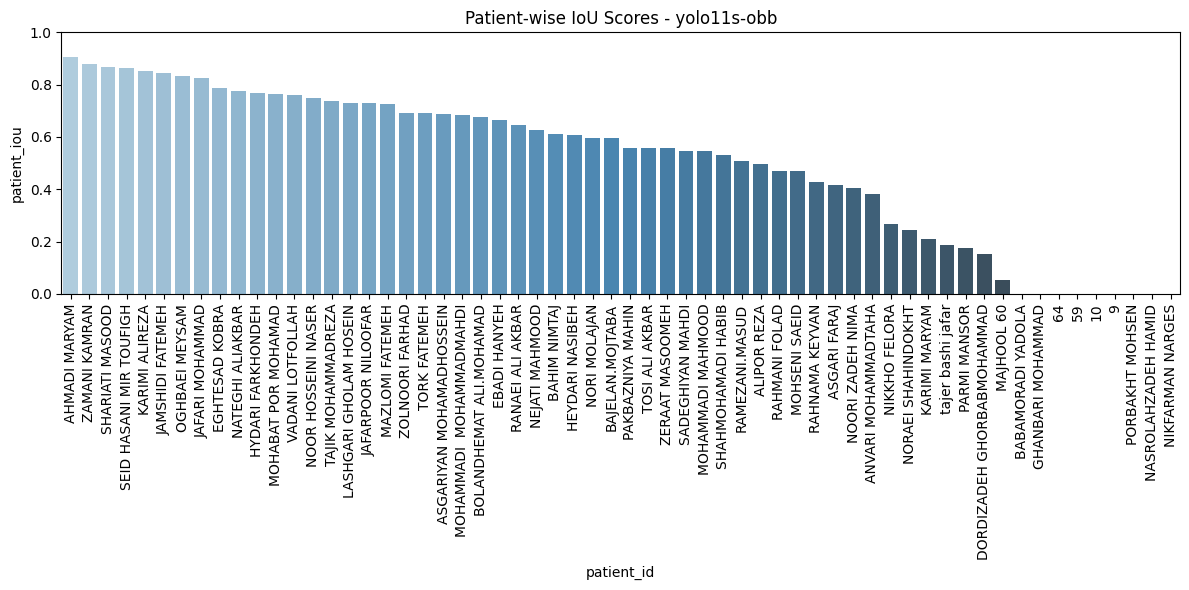

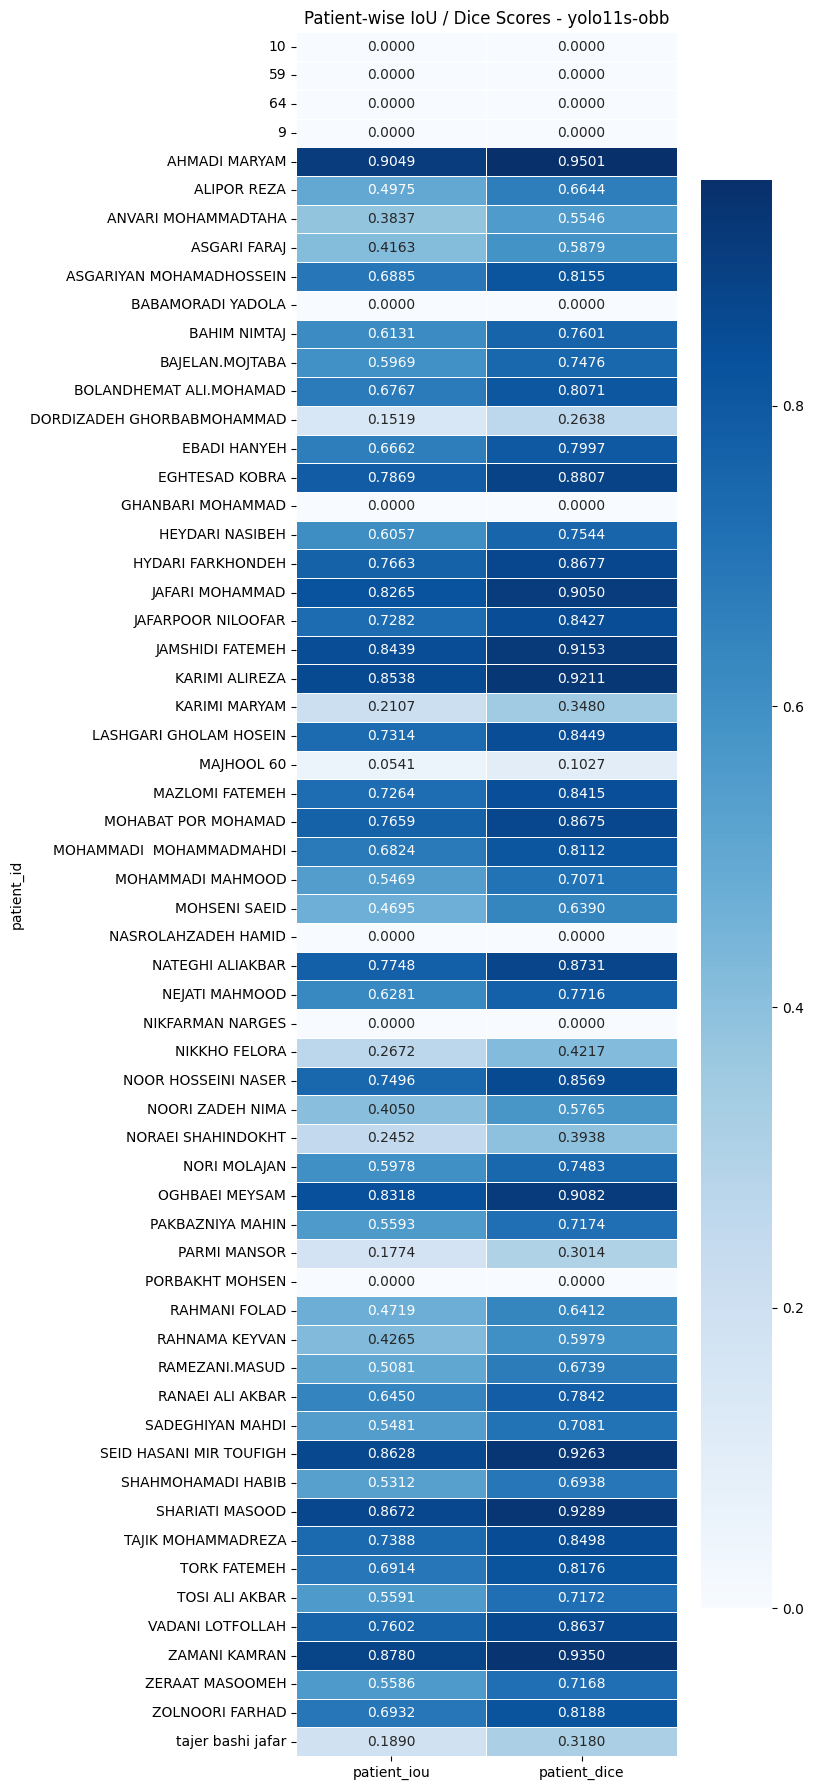


🔄 Processing YOLO model: yolo11m-obb


yolo11m-obb images:   0%|          | 0/2429 [00:00<?, ?it/s]

📢 Overall Dice (Micro-average) for yolo11m-obb: 0.7364
📢 Overall IoU (Micro-average) for yolo11m-obb: 0.5828
📊 Slice-wise Mean Dice (Macro-average) for yolo11m-obb: 0.5810
📊 Slice-wise Mean IoU (Macro-average) for yolo11m-obb: 0.5051
📄 Performing patient-wise analysis for yolo11m-obb...
📄 Patientwise scores for yolo11m-obb saved.


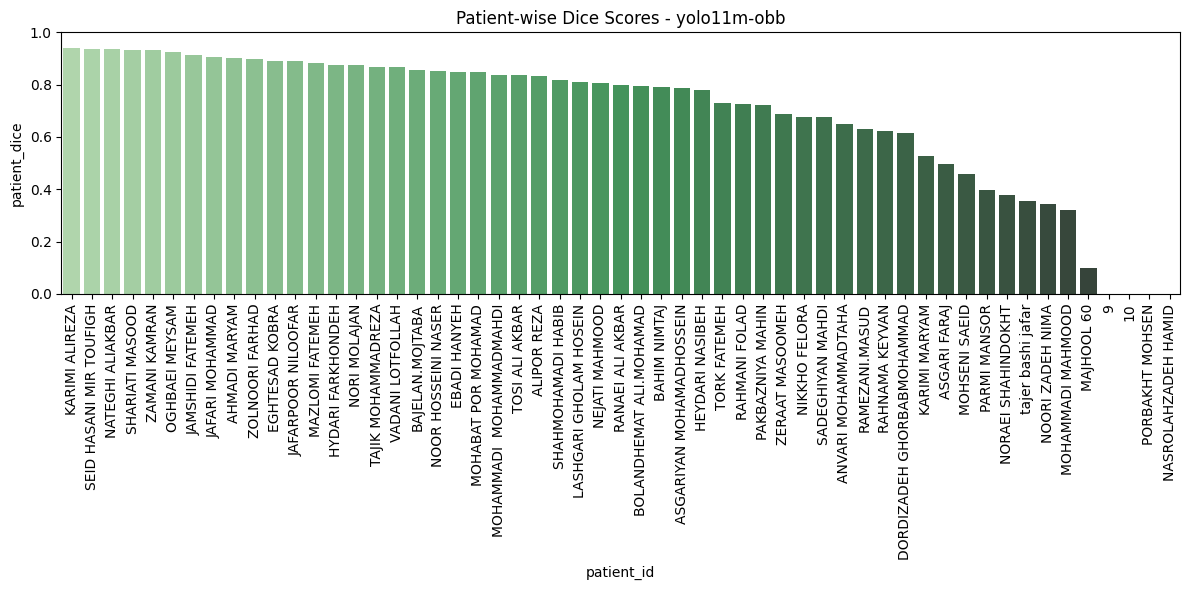

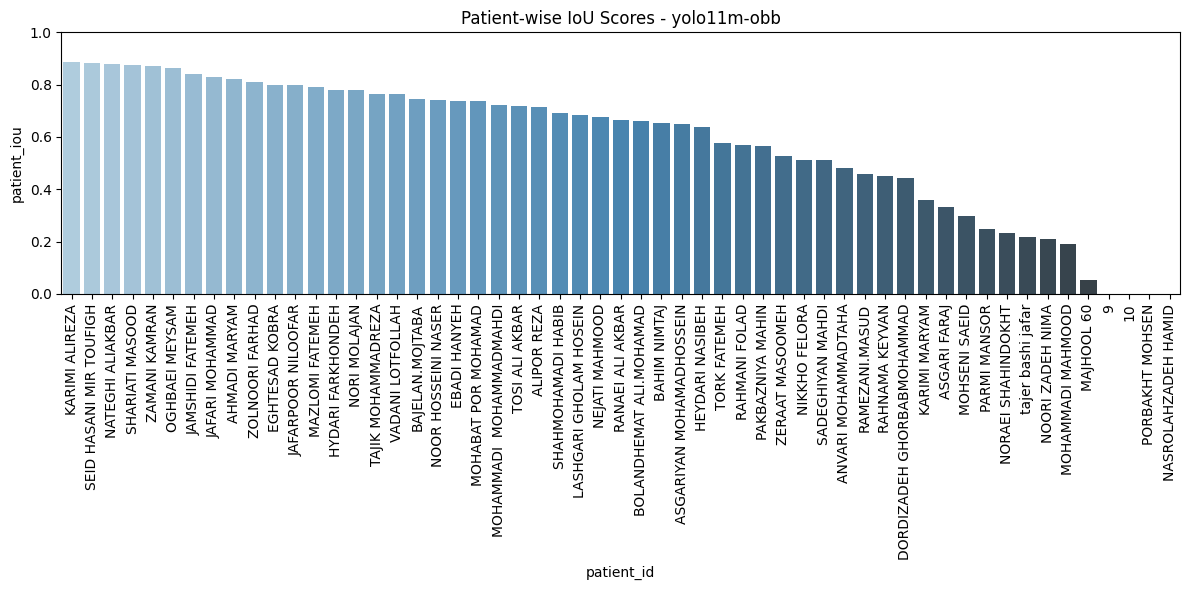

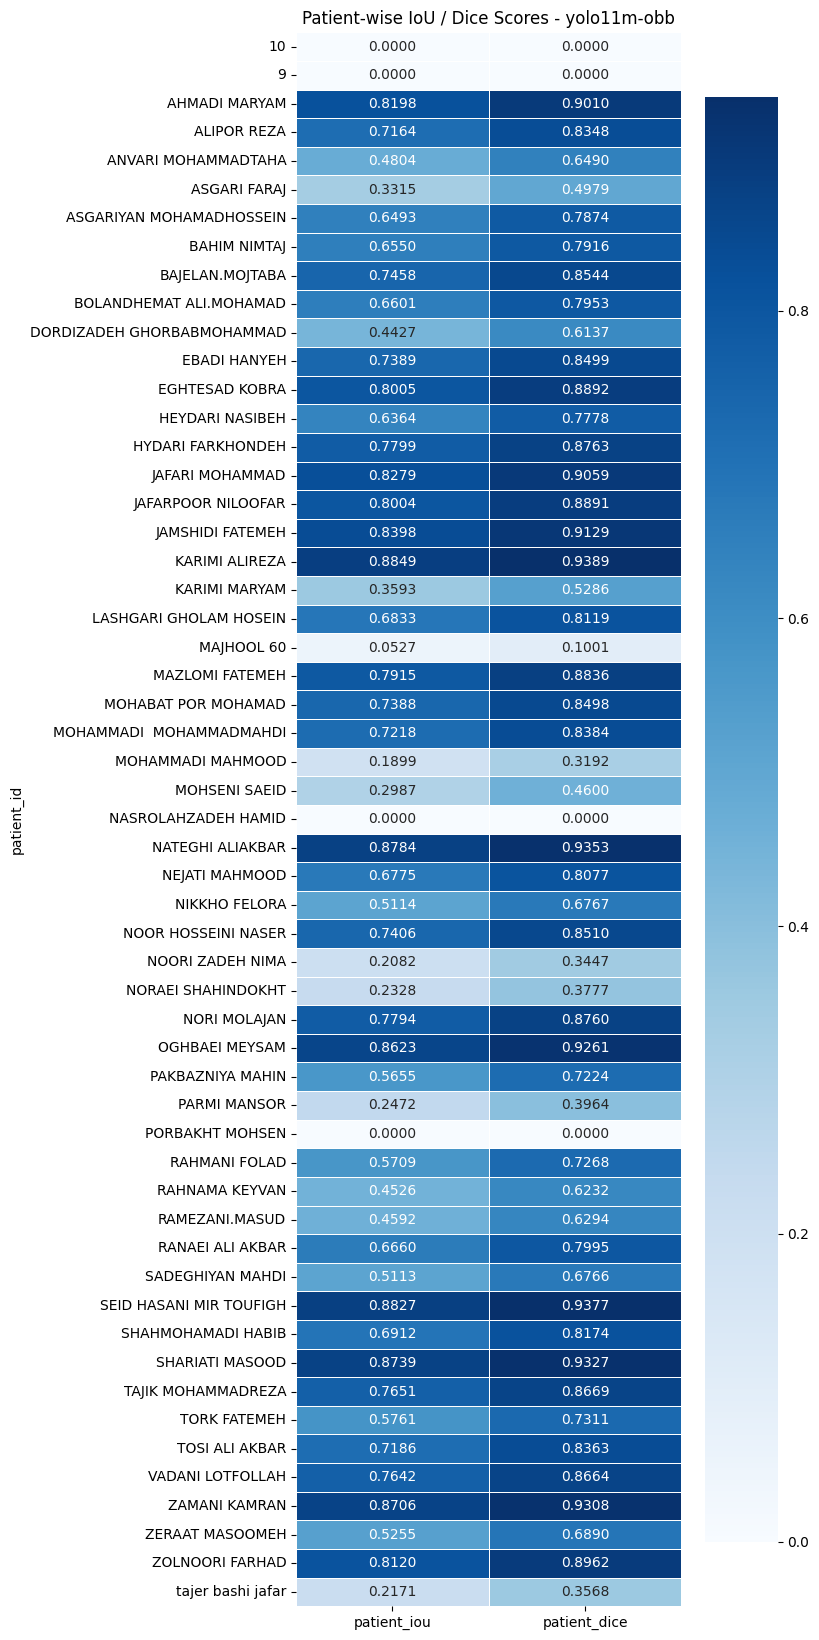

In [8]:
# --- Main processing and analysis loop ---
all_model_summaries = []
for model_name in models:
    print(f"\n🔄 Processing YOLO model: {model_name}")

    label_dir = f"/kaggle/input/r-b-obb-w-yolo-inference-on-test/inference_runs/{model_name}/labels"
    score_dir = f"/kaggle/working/scores/{model_name}"
    os.makedirs(score_dir, exist_ok=True)

    # Define accumulators for the new logic
    total_tp = 0
    total_fp = 0
    total_fn = 0
    slice_wise_dice_scores = []
    slice_wise_iou_scores = []

    csv_path = os.path.join(score_dir, f"{model_name}_scores.csv")
    with open(csv_path, 'w', newline='') as csvfile:
        fieldnames = ['image_name', 'intersection_area', 'union_area']
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        writer.writeheader()

        all_image_files = sorted(glob(os.path.join(image_dir, "*.png")))
        pbar = tqdm(all_image_files, desc=f"{model_name} images", leave=False, file=sys.stdout)

        for image_path in pbar:
            img_name = os.path.basename(image_path)
            label_path = os.path.join(label_dir, img_name.replace(".png", ".txt"))
            npy_mask_path = os.path.join(gt_mask_dir_npy, img_name.replace(".png", ".npy"))
            pbar.set_postfix_str(img_name)

            image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
            h, w = image.shape

            # Ground Truth Mask
            gt_mask = np.load(npy_mask_path) if os.path.exists(npy_mask_path) else np.zeros((h, w), dtype=np.uint8)
            gt_mask_resized = cv2.resize(gt_mask, (w, h), interpolation=cv2.INTER_NEAREST)
            gt_mask_binary = (gt_mask_resized > 0).astype(np.uint8)

            # Prediction Mask
            composite_mask = np.zeros((h, w), dtype=np.uint8)
            predictions_exist = os.path.exists(label_path) and os.path.getsize(label_path) > 0
            if predictions_exist:
                image_rgb = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
                tmp_image_path = '/kaggle/working/tmp_image.jpg'
                cv2.imwrite(tmp_image_path, image_rgb)
                with open(label_path, "r") as f:
                    lines = f.readlines()
                for line in lines:
                    parts = line.strip().split()
                    obb_coords = [float(p) for p in parts[1:-1]]
                    x_coords_norm, y_coords_norm = obb_coords[0::2], obb_coords[1::2]
                    x0, y0 = int(min(x_coords_norm) * w), int(min(y_coords_norm) * h)
                    x1, y1 = int(max(x_coords_norm) * w), int(max(y_coords_norm) * h)
                    bbox = [x0, y0, x1, y1]
                    results = sam_model(tmp_image_path, bboxes=[bbox], verbose=False)
                    if results and results[0].masks is not None:
                        mask = results[0].masks.data.squeeze().cpu().numpy().astype(np.uint8)
                        if mask.size > 0:
                            mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
                            composite_mask = np.maximum(composite_mask, mask)
            pred_mask_binary = (composite_mask > 0).astype(np.uint8)

            if gt_mask_binary.sum() == 0 and not predictions_exist:
                continue

            # Calculate TP, FP, FN for the current slice
            intersection = np.logical_and(pred_mask_binary, gt_mask_binary).sum()
            tp = int(intersection)
            fp = int(pred_mask_binary.sum() - tp)
            fn = int(gt_mask_binary.sum() - tp)

            # Update total accumulators
            total_tp += tp
            total_fp += fp
            total_fn += fn

            # Calculate and store slice-wise score for Macro-average
            slice_dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
            slice_iou = tp / (tp + fp + fn + 1e-8)
            slice_wise_dice_scores.append(slice_dice)
            slice_wise_iou_scores.append(slice_iou)

            # Write corrected data to CSV for patient-wise analysis
            writer.writerow({'image_name': img_name, 'intersection_area': tp, 'union_area': tp + fp + fn})
        pbar.close()

    # --- Final Calculation and Reporting for the model ---
    # Micro-average
    micro_dice = (2 * total_tp) / (2 * total_tp + total_fp + total_fn + 1e-8)
    micro_iou = total_tp / (total_tp + total_fp + total_fn + 1e-8)
    print(f"📢 Overall Dice (Micro-average) for {model_name}: {micro_dice:.4f}")
    print(f"📢 Overall IoU (Micro-average) for {model_name}: {micro_iou:.4f}")

    # Macro-average
    macro_dice = np.mean(slice_wise_dice_scores) if slice_wise_dice_scores else 0
    macro_iou = np.mean(slice_wise_iou_scores) if slice_wise_iou_scores else 0
    print(f"📊 Slice-wise Mean Dice (Macro-average) for {model_name}: {macro_dice:.4f}")
    print(f"📊 Slice-wise Mean IoU (Macro-average) for {model_name}: {macro_iou:.4f}")

    all_model_summaries.append({
        'model_name': model_name,
        'micro_dice': micro_dice, 'micro_iou': micro_iou,
        'macro_dice': macro_dice, 'macro_iou': macro_iou
    })

    # --- Patient-wise analysis for the current model ---
    print(f"📄 Performing patient-wise analysis for {model_name}...")
    df = pd.read_csv(csv_path)
    df['patient_id'] = df['image_name'].apply(extract_patient_name)
    patient_groups = df.groupby('patient_id')
    patientwise_results = []
    for patient_id, group in patient_groups:
        total_intersection = group['intersection_area'].sum()
        total_union = group['union_area'].sum()
        if total_union > 0:
            patient_dice = (2 * total_intersection) / (total_intersection + total_union)
            patient_iou = total_intersection / total_union
        else:
            patient_dice = 1.0 if total_intersection == 0 else 0.0
            patient_iou = 1.0 if total_intersection == 0 else 0.0
        patientwise_results.append({'patient_id': patient_id, 'patient_dice': patient_dice, 'patient_iou': patient_iou})
    
    patientwise_df = pd.DataFrame(patientwise_results)
    patientwise_dir = os.path.join(score_dir, "patientwise")
    os.makedirs(patientwise_dir, exist_ok=True)
    patientwise_df.to_csv(os.path.join(patientwise_dir, f"{model_name}_patientwise_scores.csv"), index=False)
    print(f"📄 Patientwise scores for {model_name} saved.")
    
    # --- Patient-wise PLOTS ---
    patientwise_plot_dir = os.path.join(output_dir, "patientwise_plots", model_name)
    os.makedirs(patientwise_plot_dir, exist_ok=True)

    # Dice Barplot
    plt.figure(figsize=(12, 6))
    sorted_patient_dice = patientwise_df.sort_values(by="patient_dice", ascending=False)
    sns.barplot(data=sorted_patient_dice, x="patient_id", y="patient_dice", palette="Greens_d")
    plt.title(f"Patient-wise Dice Scores - {model_name}")
    plt.ylim(0, 1.0)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.savefig(os.path.join(patientwise_plot_dir, f"{model_name}_Patientwise_Dice_BarPlot.png"), dpi=300)
    plt.show()

    # IoU Barplot
    plt.figure(figsize=(12, 6))
    sorted_patient_iou = patientwise_df.sort_values(by="patient_iou", ascending=False)
    sns.barplot(data=sorted_patient_iou, x="patient_id", y="patient_iou", palette="Blues_d")
    plt.title(f"Patient-wise IoU Scores - {model_name}")
    plt.ylim(0, 1.0)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.savefig(os.path.join(patientwise_plot_dir, f"{model_name}_Patientwise_IoU_BarPlot.png"), dpi=300)
    plt.show()

    # Heatmap
    heatmap_data = patientwise_df.set_index('patient_id')[['patient_iou', 'patient_dice']]
    plt.figure(figsize=(8, max(6, len(heatmap_data) * 0.3)))
    sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap="Blues", linewidths=0.5)
    plt.title(f"Patient-wise IoU / Dice Scores - {model_name}")
    plt.tight_layout()
    plt.savefig(os.path.join(patientwise_plot_dir, f"{model_name}_Patientwise_Heatmap.png"), dpi=300)
    plt.show()


In [9]:
# --- Save final summary and create plots ---
summary_df = pd.DataFrame(all_model_summaries)
summary_path = os.path.join(output_dir, "binary_obb_summary.csv")
summary_df.to_csv(summary_path, index=False)
print(f"\n✅ All model summaries saved to: {summary_path}")


✅ All model summaries saved to: /kaggle/working/myplots/binary_obb_summary.csv


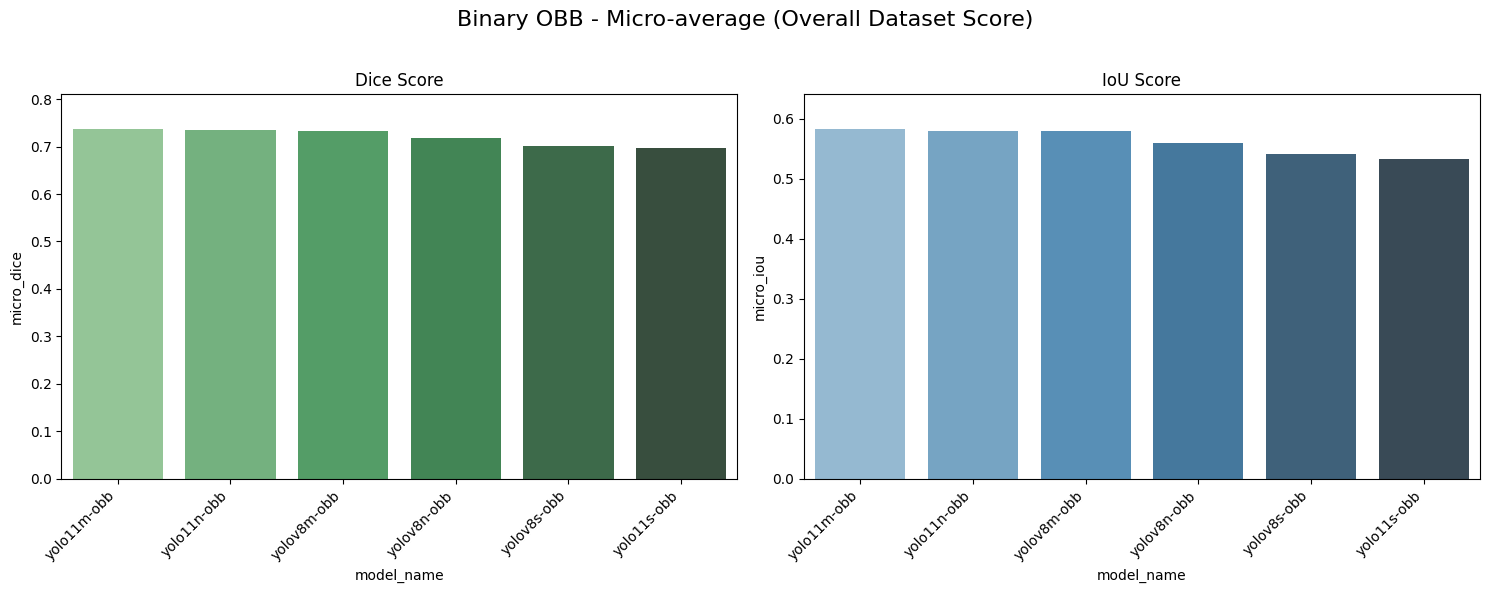

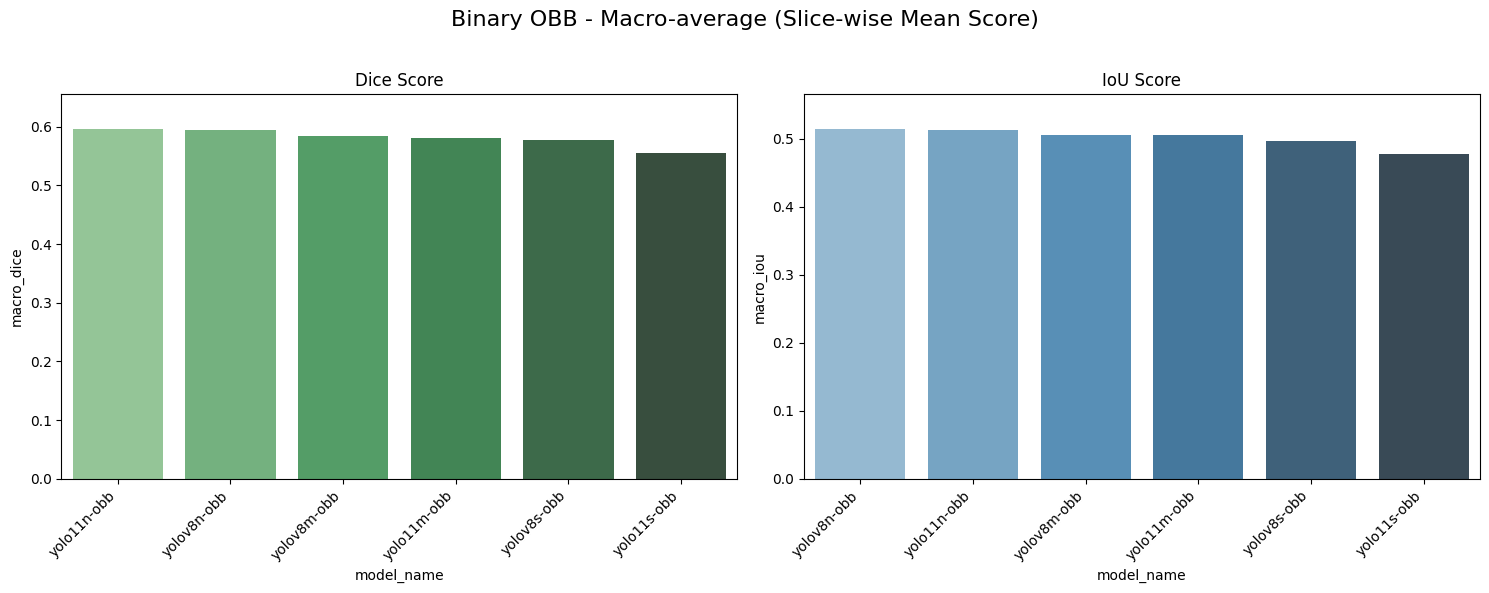

In [10]:
# --- Plotting ---
# Plot 1: Micro-average Scores
plt.figure(figsize=(15, 6))
plt.suptitle('Binary OBB - Micro-average (Overall Dataset Score)', fontsize=16)
plt.subplot(1, 2, 1)
sorted_dice = summary_df.sort_values(by="micro_dice", ascending=False)
sns.barplot(data=sorted_dice, x="model_name", y="micro_dice", palette="Greens_d")
plt.title("Dice Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(0.4, summary_df['micro_dice'].max() * 1.1))

plt.subplot(1, 2, 2)
sorted_iou = summary_df.sort_values(by="micro_iou", ascending=False)
sns.barplot(data=sorted_iou, x="model_name", y="micro_iou", palette="Blues_d")
plt.title("IoU Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(0.4, summary_df['micro_iou'].max() * 1.1))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(output_dir, "Binary_OBB_Micro_Average_Scores.png"), dpi=300)
plt.show()

# Plot 2: Macro-average Scores
plt.figure(figsize=(15, 6))
plt.suptitle('Binary OBB - Macro-average (Slice-wise Mean Score)', fontsize=16)
plt.subplot(1, 2, 1)
sorted_dice = summary_df.sort_values(by="macro_dice", ascending=False)
sns.barplot(data=sorted_dice, x="model_name", y="macro_dice", palette="Greens_d")
plt.title("Dice Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(0.4, summary_df['macro_dice'].max() * 1.1))

plt.subplot(1, 2, 2)
sorted_iou = summary_df.sort_values(by="macro_iou", ascending=False)
sns.barplot(data=sorted_iou, x="model_name", y="macro_iou", palette="Blues_d")
plt.title("IoU Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(0.4, summary_df['macro_iou'].max() * 1.1))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(output_dir, "Binary_OBB_Macro_Average_Scores.png"), dpi=300)
plt.show()

In [11]:
!zip -r /kaggle/working/myplots.zip /kaggle/working/myplots

  adding: kaggle/working/myplots/ (stored 0%)
  adding: kaggle/working/myplots/Binary_OBB_Macro_Average_Scores.png (deflated 26%)
  adding: kaggle/working/myplots/Binary_OBB_Micro_Average_Scores.png (deflated 26%)
  adding: kaggle/working/myplots/patientwise_plots/ (stored 0%)
  adding: kaggle/working/myplots/patientwise_plots/yolov8m-obb/ (stored 0%)
  adding: kaggle/working/myplots/patientwise_plots/yolov8m-obb/yolov8m-obb_Patientwise_IoU_BarPlot.png (deflated 14%)
  adding: kaggle/working/myplots/patientwise_plots/yolov8m-obb/yolov8m-obb_Patientwise_Heatmap.png (deflated 9%)
  adding: kaggle/working/myplots/patientwise_plots/yolov8m-obb/yolov8m-obb_Patientwise_Dice_BarPlot.png (deflated 14%)
  adding: kaggle/working/myplots/patientwise_plots/yolo11m-obb/ (stored 0%)
  adding: kaggle/working/myplots/patientwise_plots/yolo11m-obb/yolo11m-obb_Patientwise_Dice_BarPlot.png (deflated 14%)
  adding: kaggle/working/myplots/patientwise_plots/yolo11m-obb/yolo11m-obb_Patientwise_IoU_BarPlot.pn